# RBF SVM Classifier for rest_int Classification

**Target:** `rest_int` (0: 1min, 1: 5min, 2: 10min rest)

**Method:**
- **RBF SVM** classifier via `SVC(kernel='rbf')`
- **PCA** for dimensionality reduction before SVM
- **StratifiedKFold** for hyperparameter tuning
- **Grid Search** over hyperparameters
- **MCCV:** 10 random train/test splits by user_id

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, confusion_matrix

In [2]:
# Load data (use dataset_filtered_1_450.csv for full PSD; fallback to bands)
import os

if os.path.exists("dataset_filtered_1_450.csv"):
    df = pd.read_csv("dataset_filtered_1_450.csv")
    meta_cols = ["user_id", "rest_int", "exp", "seq"]
    feature_cols = [c for c in df.columns if c not in meta_cols]
    print(f"Loaded dataset_filtered_1_450.csv: {len(df)} samples, {len(feature_cols)} features")
else:
    df = pd.read_csv("dataset_filtered_bands.csv")
    meta_cols = ["user_id", "rest_int", "exp", "seq"]
    feature_cols = [c for c in df.columns if c not in meta_cols]
    print(f"Loaded dataset_filtered_bands.csv (fallback): {len(df)} samples, {len(feature_cols)} features")

unique_users = df["user_id"].unique()
n_users = len(unique_users)
n_train_users = int(n_users * 0.8)
n_test_users = n_users - n_train_users

print(f"MCCV split: {n_train_users} train users, {n_test_users} test users per run")

Loaded dataset_filtered_1_450.csv: 243 samples, 1350 features
MCCV split: 11 train users, 3 test users per run


In [3]:
# Pipeline: StandardScaler -> PCA -> RBF SVM
# PCA n_components: explore total PCs and 80% variance before grid search
X_full = df[feature_cols].values
X_scaled = StandardScaler().fit_transform(X_full)
max_pc = min(len(feature_cols), len(df) - 1)
pca_explore = PCA(n_components=max_pc, random_state=42).fit(X_scaled)
cumvar = np.cumsum(pca_explore.explained_variance_ratio_)
n_pc_80 = np.searchsorted(cumvar, 0.8) + 1  # 1-based count for 80% variance
print(f"Total PCs (max): {max_pc}")
print(f"PCs to capture 80% variance: {n_pc_80}")
print(f"Actual variance at {n_pc_80} PCs: {cumvar[n_pc_80-1]:.4f}")

# PC range: 2 to min(n_pc_80, 20), capped by max_pc
pc_max = min(n_pc_80, 20, max_pc)
n_components_options = [n for n in [2, 3, 4, 5, 10, 15, 20] if n <= pc_max]
if pc_max > 20 and pc_max not in n_components_options:
    n_components_options.append(pc_max)
    n_components_options.sort()
if not n_components_options:
    n_components_options = [min(10, max_pc)]

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=42)),
    ("svc", SVC(kernel="rbf", random_state=42)),
])

param_grid = {
    "pca__n_components": n_components_options,
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", "auto"],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
print(f"Grid: n_components={n_components_options}, C=[0.1,1,10,100], gamma=['scale','auto']")

Total PCs (max): 242
PCs to capture 80% variance: 3
Actual variance at 3 PCs: 0.8494
Grid: n_components=[2, 3], C=[0.1,1,10,100], gamma=['scale','auto']


In [4]:
# MCCV: 10 random train/test splits by user_id
N_MCCV = 10
MCCV_SEEDS = list(range(42, 42 + N_MCCV))

mccv_f1 = []
mccv_acc = []
mccv_cm_list = []
best_params_list = []

for run, seed in enumerate(MCCV_SEEDS):
    np.random.seed(seed)
    shuffled_users = np.random.permutation(unique_users)
    train_users = shuffled_users[:n_train_users]
    test_users = shuffled_users[n_train_users:]

    train_mask = df["user_id"].isin(train_users)
    test_mask = df["user_id"].isin(test_users)
    df_train = df[train_mask]
    df_test = df[test_mask]

    X_train = df_train[feature_cols].values
    y_train = df_train["rest_int"].values
    X_test = df_test[feature_cols].values
    y_test = df_test["rest_int"].values

    grid_search = GridSearchCV(
        pipe, param_grid, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0
    )
    grid_search.fit(X_train, y_train)

    y_pred = grid_search.best_estimator_.predict(X_test)
    f1 = f1_score(y_test, y_pred, average="weighted")
    acc = (y_pred == y_test).mean()
    cm = confusion_matrix(y_test, y_pred)

    mccv_f1.append(f1)
    mccv_acc.append(acc)
    mccv_cm_list.append(cm)
    best_params_list.append(grid_search.best_params_)

    print(f"Run {run+1}/{N_MCCV} (seed={seed}): F1={f1:.4f}, Acc={acc:.4f}  best={grid_search.best_params_}")

Run 1/10 (seed=42): F1=0.2230, Acc=0.2745  best={'pca__n_components': 2, 'svc__C': 100, 'svc__gamma': 'scale'}
Run 2/10 (seed=43): F1=0.2464, Acc=0.2593  best={'pca__n_components': 3, 'svc__C': 100, 'svc__gamma': 'scale'}
Run 3/10 (seed=44): F1=0.3089, Acc=0.3148  best={'pca__n_components': 3, 'svc__C': 100, 'svc__gamma': 'scale'}
Run 4/10 (seed=45): F1=0.3415, Acc=0.3519  best={'pca__n_components': 3, 'svc__C': 100, 'svc__gamma': 'scale'}
Run 5/10 (seed=46): F1=0.3815, Acc=0.4259  best={'pca__n_components': 3, 'svc__C': 100, 'svc__gamma': 'scale'}
Run 6/10 (seed=47): F1=0.2927, Acc=0.3137  best={'pca__n_components': 3, 'svc__C': 10, 'svc__gamma': 'scale'}
Run 7/10 (seed=48): F1=0.2354, Acc=0.2778  best={'pca__n_components': 3, 'svc__C': 100, 'svc__gamma': 'scale'}
Run 8/10 (seed=49): F1=0.3077, Acc=0.3333  best={'pca__n_components': 3, 'svc__C': 100, 'svc__gamma': 'scale'}
Run 9/10 (seed=50): F1=0.3295, Acc=0.3519  best={'pca__n_components': 3, 'svc__C': 100, 'svc__gamma': 'scale'}
Ru

In [5]:
# MCCV summary
print("--- MCCV Results (10 random train/test splits by user_id) ---")
print(f"Weighted F1: {np.mean(mccv_f1):.4f} ± {np.std(mccv_f1):.4f}")
print(f"Accuracy:     {np.mean(mccv_acc):.4f} ± {np.std(mccv_acc):.4f}")

mean_cm = np.mean(mccv_cm_list, axis=0).round(1)
print("\n--- Mean Confusion Matrix (across 10 runs) ---")
print(mean_cm)
print("(rows: 1min, 5min, 10min; cols: predicted)")

from collections import Counter
param_strs = [str(p) for p in best_params_list]
most_common = Counter(param_strs).most_common(1)[0]
print(f"\nMost frequent best params: {most_common[0]} (in {most_common[1]}/10 runs)")

--- MCCV Results (10 random train/test splits by user_id) ---
Weighted F1: 0.2908 ± 0.0500
Accuracy:     0.3256 ± 0.0467

--- Mean Confusion Matrix (across 10 runs) ---
[[7.5 5.8 4.1]
 [5.9 3.  8.5]
 [4.8 6.5 6.7]]
(rows: 1min, 5min, 10min; cols: predicted)

Most frequent best params: {'pca__n_components': 3, 'svc__C': 100, 'svc__gamma': 'scale'} (in 8/10 runs)


## Comparison 1: With PCA vs Without PCA

MCCV 10 runs, paired comparison. Bar chart with significance (paired t-test).

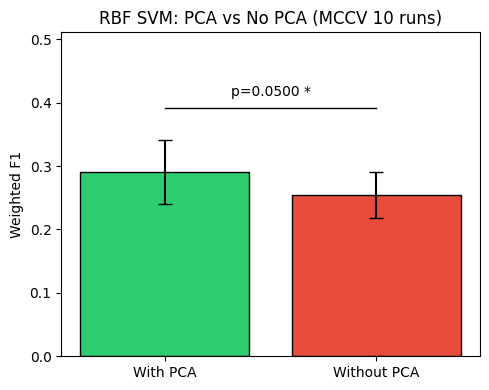

With PCA:  0.2908 ± 0.0500
Without PCA: 0.2539 ± 0.0361
Paired t-test: p = 0.0500 *


In [6]:
# PCA vs Without PCA: MCCV 10 runs
pipe_with_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=42)),
    ("svc", SVC(kernel="rbf", random_state=42)),
])
param_with_pca = {
    "pca__n_components": n_components_options,
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", "auto"],
}

pipe_no_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", random_state=42)),
])
param_no_pca = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", "auto"],
}

f1_with_pca, f1_no_pca = [], []
for run, seed in enumerate(MCCV_SEEDS):
    np.random.seed(seed)
    shuffled_users = np.random.permutation(unique_users)
    train_users = shuffled_users[:n_train_users]
    test_users = shuffled_users[n_train_users:]
    train_mask = df["user_id"].isin(train_users)
    test_mask = df["user_id"].isin(test_users)
    X_train = df[train_mask][feature_cols].values
    y_train = df[train_mask]["rest_int"].values
    X_test = df[test_mask][feature_cols].values
    y_test = df[test_mask]["rest_int"].values

    gs_pca = GridSearchCV(pipe_with_pca, param_with_pca, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0)
    gs_pca.fit(X_train, y_train)
    f1_with_pca.append(f1_score(y_test, gs_pca.best_estimator_.predict(X_test), average="weighted"))

    gs_no = GridSearchCV(pipe_no_pca, param_no_pca, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0)
    gs_no.fit(X_train, y_train)
    f1_no_pca.append(f1_score(y_test, gs_no.best_estimator_.predict(X_test), average="weighted"))

# Paired t-test
t_stat, p_val = stats.ttest_rel(f1_with_pca, f1_no_pca)
sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

# Bar chart with significance
fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(2)
means = [np.mean(f1_with_pca), np.mean(f1_no_pca)]
stds = [np.std(f1_with_pca), np.std(f1_no_pca)]
bars = ax.bar(x, means, yerr=stds, capsize=5, color=["#2ecc71", "#e74c3c"], edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(["With PCA", "Without PCA"])
ax.set_ylabel("Weighted F1")
ax.set_title("RBF SVM: PCA vs No PCA (MCCV 10 runs)")
ymax = max(means) + max(stds) + 0.05
ax.plot([0, 1], [ymax, ymax], "k-", lw=1)
ax.text(0.5, ymax + 0.02, f"p={p_val:.4f} {sig}", ha="center", fontsize=10)
ax.set_ylim(0, ymax + 0.12)
plt.tight_layout()
plt.show()
print(f"With PCA:  {np.mean(f1_with_pca):.4f} ± {np.std(f1_with_pca):.4f}")
print(f"Without PCA: {np.mean(f1_no_pca):.4f} ± {np.std(f1_no_pca):.4f}")
print(f"Paired t-test: p = {p_val:.4f} {sig}")

## Comparison 2: Subject-specific vs Generalized Models

- **Generalized**: Train on 11 users, test on 3 held-out users (current setup)
- **Subject-specific**: For each test user, train only on that user's data (with CV), test on held-out portion

/Users/shikaiyi/miniforge3/envs/Neural/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(
/Users/shikaiyi/miniforge3/envs/Neural/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(
/Users/shikaiyi/miniforge3/envs/Neural/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(
/Users/shikaiyi/miniforge3/envs/Neural/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=2.
  warnings.warn(


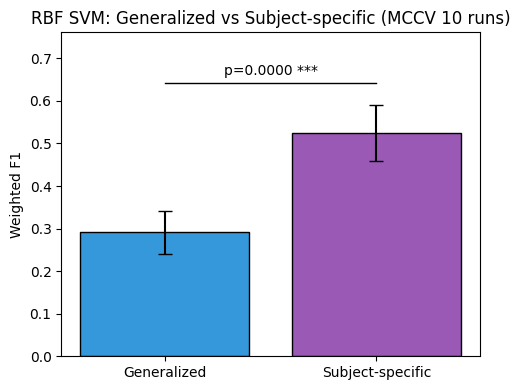

Generalized: 0.2908 ± 0.0500
Subject-specific: 0.5243 ± 0.0667
Paired t-test: p = 0.0000 ***


In [7]:
# Subject-specific vs Generalized: MCCV 10 runs
f1_generalized, f1_subject_specific = [], []
for run, seed in enumerate(MCCV_SEEDS):
    np.random.seed(seed)
    shuffled_users = np.random.permutation(unique_users)
    train_users = shuffled_users[:n_train_users]
    test_users = shuffled_users[n_train_users:]

    # Generalized: train on 11 users, test on 3 users
    train_mask = df["user_id"].isin(train_users)
    test_mask = df["user_id"].isin(test_users)
    X_train_g = df[train_mask][feature_cols].values
    y_train_g = df[train_mask]["rest_int"].values
    X_test_all = df[test_mask][feature_cols].values
    y_test_all = df[test_mask]["rest_int"].values
    gs_g = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_weighted", n_jobs=-1, verbose=0)
    gs_g.fit(X_train_g, y_train_g)
    f1_generalized.append(f1_score(y_test_all, gs_g.best_estimator_.predict(X_test_all), average="weighted"))

    # Subject-specific: for each test user, train on that user only, test on held-out
    f1_per_user = []
    for uid in test_users:
        df_u = df[df["user_id"] == uid]
        X_u = df_u[feature_cols].values
        y_u = df_u["rest_int"].values
        if len(y_u) < 6:  # need enough for CV
            f1_per_user.append(0.0)
            continue
        n_splits = min(3, len(y_u) // 6) or 2
        skf_u = StratifiedKFold(n_splits=max(2, n_splits), shuffle=True, random_state=42)
        preds, truths = [], []
        for tr_idx, te_idx in skf_u.split(X_u, y_u):
            gs_u = GridSearchCV(pipe, param_grid, cv=2, scoring="f1_weighted", n_jobs=-1, verbose=0)
            gs_u.fit(X_u[tr_idx], y_u[tr_idx])
            preds.extend(gs_u.best_estimator_.predict(X_u[te_idx]))
            truths.extend(y_u[te_idx])
        f1_per_user.append(f1_score(truths, preds, average="weighted"))
    f1_subject_specific.append(np.mean(f1_per_user))

# Paired t-test
t_stat, p_val = stats.ttest_rel(f1_generalized, f1_subject_specific)
sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

# Bar chart
fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(2)
means = [np.mean(f1_generalized), np.mean(f1_subject_specific)]
stds = [np.std(f1_generalized), np.std(f1_subject_specific)]
ax.bar(x, means, yerr=stds, capsize=5, color=["#3498db", "#9b59b6"], edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(["Generalized", "Subject-specific"])
ax.set_ylabel("Weighted F1")
ax.set_title("RBF SVM: Generalized vs Subject-specific (MCCV 10 runs)")
ymax = max(means) + max(stds) + 0.05
ax.plot([0, 1], [ymax, ymax], "k-", lw=1)
ax.text(0.5, ymax + 0.02, f"p={p_val:.4f} {sig}", ha="center", fontsize=10)
ax.set_ylim(0, ymax + 0.12)
plt.tight_layout()
plt.show()
print(f"Generalized: {np.mean(f1_generalized):.4f} ± {np.std(f1_generalized):.4f}")
print(f"Subject-specific: {np.mean(f1_subject_specific):.4f} ± {np.std(f1_subject_specific):.4f}")
print(f"Paired t-test: p = {p_val:.4f} {sig}")